# Benchmark: a Student-t mean and a Student-t scale

A Student-t distribution models heavier tails than a Gaussian on the real line. A Student-t with 4 degrees of freedom has a finite variance, and that variance is not the scale parameter: `sd = sigma * sqrt(df / (df - 2))`. This study asks whether `StudentTLSS` recovers the mean, the scale and the degrees of freedom, against statsmodels' `TLinearModel`, which maximises the same likelihood with one scale. OLS is the Gaussian comparison. scikit-learn has no t regression.

Two tasks, four standard normal predictors, `noise` unused, 1,500 training rows and one 4,000-row test sample. Four training seeds.

* **constant**: `mu = 0.30 + 0.80 x1 - 0.35 x2` and `sigma = 1.25`.
* **varying**: `mu = 0.10 + sin(1.4 x1) + 0.25 x2` and `log sigma = 0.10 + 0.55 sin(2 x3)`.

The degrees of freedom of the t distribution, `df`, are 4 in both. `StudentTLSS` uses an identity link for `mu` and log links for `sigma` and `df`. Step counts are chosen by 5-fold cross-validation over every step, `nu = 0.1`, non-cyclic (each step updates only the parameter whose update most lowers the risk), with a cap of 600 linear steps and 1,200 smooth steps. A fit that does not converge is left out of the means below; none did, and no mboostrs path put its selected step on the cap.


:::{note} Recorded before the response-units change
The mboostrs `StudentTLSS` results on this page are recorded results. They were recorded with mboostrs 0.2.3 or earlier, when distributional (LSS) and `Quantile` fits boosted the response in the units it was given. Since then these fits divide the response by its standard deviation, boost the rescaled response and map the fitted model back (`response_scale="auto"`), so a step has the same size in any units; `Quantile` also starts at the `tau`-quantile of the response, and takes steps of 0.3 when no control is given. Refitting on the current version gives different numbers. `response_scale=None` with the settings the page states reproduces the recorded fits; [Response units](../implementation/parity_and_bugs.ipynb#response-units) describes the change and its measured effect.
:::

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the conditional distribution of a heavy-tailed response |
| **Observed response** | a simulated Student-t draw, degrees of freedom 4 |
| **Estimand** | test mean negative log density; absolute error of the mean, of log scale and of df |
| **Units** | nats per row; the response is on the real line |
| **Sampling unit** | one simulated observation per row |
| **Dependence** | independently generated rows |
| **Uncertainty** | means across four independently generated training samples, evaluated on one shared independent test sample per task; no sampling intervals are reported |
| **Claim type** | methodological comparison on simulated data |
| **Sampling** | one shared test sample per task; four training seeds |
| **What is held fixed** | the same rows for every method; `sigma` is the t scale |
| **What this does not estimate** | a quantile, a Gaussian location-scale model, or a comparison with R |

:::


## Reproduction

From the repository root, with `statsmodels`, `scipy` and `patsy` installed:

```bash
RAYON_NUM_THREADS=1 OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 \
    python benches/bench_studentt.py --out docs/book/cases/bench_studentt.json
```

The tables below read that file.

The output file records the library versions and the protocol in `provenance`. Timing standard
deviations and standard errors describe variation across the training
seeds. Each method has its own fit, tuning and prediction workload, as
defined by the runner; these elapsed times describe those workflows.


In [1]:
# Read the recorded runs; this page does not refit the models.
import json
from pathlib import Path

import altair as alt
import polars as pl

from bench_tables import table

bench = json.loads(Path("bench_studentt.json").read_text())


def finite(value):
    if value is None or value != value or value in (float("inf"), float("-inf")):
        return None
    return value


In [2]:
# Preserve the recorded method and replication for each score.
rows = []
for record in bench["results"]:
    if record.get("converged") is False:
        continue
    rows.append({
        "task": record["task"],
        "method": record["method"],
        "own_nll": finite(record["own_nll"]),
        "nll_true": finite(record["nll_at_true_scale"]),
        "mae": finite(record["mae"]),
        "mae_log_sigma": finite(record["mae_log_sigma"]),
        "mae_df": finite(record["mae_df"]),
        "df": finite(record["df_mean"]),
        "seconds": record["seconds"],
        "mstop": record.get("mstop"),
    })
raw = pl.DataFrame(rows)


In [3]:
# Average the recorded scores within each task and method.
summary = (
    raw.group_by("task", "method")
    .agg(
        pl.col("own_nll").mean(),
        pl.col("nll_true").mean(),
        pl.col("mae").mean(),
        pl.col("mae_log_sigma").mean(),
        pl.col("mae_df").mean(),
        pl.col("df").mean(),
        pl.col("seconds").mean(),
        pl.col("mstop").mean(),
        pl.col("own_nll").count().alias("n_finite"),
    )
    .sort("task", "own_nll")
)


In [4]:
# Retrieve recorded scores and convergence evidence for the interpretation.
def value(task, method, column):
    hit = summary.filter((pl.col("task") == task) & (pl.col("method") == method))
    return float(hit[column][0])


def probe(label):
    return next(item for item in bench["usability"]["probes"] if item["label"] == label)


In [5]:
scored = summary.filter(pl.col("method") != "generating Student-t")
table(
    scored.select("task", "method", "own_nll", "nll_true", "mae", "mae_log_sigma", "df", "seconds"),
    title="Student-t mean and scale",
    subtitle="Mean over four seeds; 1,500 training rows and 4,000 test rows",
    group="task",
    labels={
        "own_nll": "own log score",
        "nll_true": "at true scale",
        "mae": "MAE",
        "mae_log_sigma": "log-scale MAE",
        "df": "mean df",
        "seconds": "seconds",
    },
    better={"own_nll": "min", "mae": "min", "mae_log_sigma": "min"},
    formats={"nll_true": 4, "df": 2, "seconds": 3},
    notes=(
        "Own log score is the test negative log density, in nats per row: "
        "the t density for StudentTLSS and TLinearModel, the Gaussian density for OLS. "
        "At true scale scores every predicted mean with the generating sigma and df. "
        "sigma is the t scale, not the standard deviation. "
        "OLS has no t scale, so its log-scale MAE and df are blank. "
        "Lower is better. Bold marks the best scored value in each task."
    ),
)


GT(_tbl_data=shape: (8, 8)
┌──────────┬───────────────┬──────────┬──────────┬──────────┬───────────────┬──────────┬───────────┐
│ task     ┆ method        ┆ own_nll  ┆ nll_true ┆ mae      ┆ mae_log_sigma ┆ df       ┆ seconds   │
│ ---      ┆ ---           ┆ ---      ┆ ---      ┆ ---      ┆ ---           ┆ ---      ┆ ---       │
│ str      ┆ str           ┆ f64      ┆ f64      ┆ f64      ┆ f64           ┆ f64      ┆ f64       │
╞══════════╪═══════════════╪══════════╪══════════╪══════════╪═══════════════╪══════════╪═══════════╡
│ constant ┆ statsmodels   ┆ 1.920521 ┆ 1.920154 ┆ 0.071724 ┆ 0.028273      ┆ 3.967542 ┆ 0.012284  │
│          ┆ TLinearModel  ┆          ┆          ┆          ┆               ┆          ┆           │
│ constant ┆ mboostrs      ┆ 1.922664 ┆ 1.919555 ┆ 0.067797 ┆ 0.057212      ┆ 4.585848 ┆ 2.650405  │
│          ┆ glmboostLSS   ┆          ┆          ┆          ┆               ┆          ┆           │
│          ┆ StudentTL…    ┆          ┆          ┆          ┆               ┆          ┆           │
│ constant ┆ statsmodels   ┆ 2.046634 ┆ 1.920836 ┆ 0.087695 ┆ null          ┆ null     ┆ 0.000304  │
│          ┆ OLS           ┆          ┆          ┆          ┆               ┆          ┆           │
│ varying  ┆ mboostrs      ┆ 1.781329 ┆ 1.777304 ┆ 0.084146 ┆ 0.067181      ┆ 3.961798 ┆ 12.253778 │
│          ┆ gamboostLSS   ┆          ┆          ┆          ┆               ┆          ┆           │
│          ┆ StudentTL…    ┆          ┆          ┆          ┆               ┆          ┆           │
│ varying  ┆ statsmodels   ┆ 1.860372 ┆ 1.779181 ┆ 0.101107 ┆ 0.351427      ┆ 2.847975 ┆ 0.120334  │
│          ┆ TLinearModel  ┆          ┆          ┆          ┆               ┆          ┆           │
│          ┆ splin…        ┆          ┆          ┆          ┆               ┆          ┆           │
│ varying  ┆ mboostrs      ┆ 1.89794  ┆ 1.842124 ┆ 0.353651 ┆ 0.326425      ┆ 3.826842 ┆ 2.66139   │
│          ┆ glmboostLSS   ┆          ┆          ┆          ┆               ┆          ┆           │
│          ┆ StudentTL…    ┆          ┆          ┆          ┆               ┆          ┆           │
│ varying  ┆ statsmodels   ┆ 1.903686 ┆ 1.841026 ┆ 0.343339 ┆ 0.352707      ┆ 3.092585 ┆ 0.012043  │
│          ┆ TLinearModel  ┆          ┆          ┆          ┆               ┆          ┆           │
│ varying  ┆ statsmodels   ┆ 2.039344 ┆ 1.84564  ┆ 0.361948 ┆ null          ┆ null     ┆ 0.000307  │
│          ┆ OLS           ┆          ┆          ┆          ┆               ┆          ┆           │
└──────────┴───────────────┴──────────┴──────────┴──────────┴───────────────┴──────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10e4118e0>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.row_group: 3>, column_label='task', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='own_nll', type=<ColInfoTypeEnum.default: 1>, column_label='own log score', column_align='right', column_width=None), ColInfo(var='nll_true', type=<ColInfoTypeEnum.default: 1>, column_label='at true scale', column_align='right', column_width=None), ColInfo(var='mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE', column_align='right', column_width=None), ColInfo(var='mae_log_sigma', type=<ColInfoTypeEnum.default: 1>, column_label='log-scale MAE', column_align='right', column_width=None), ColInfo(var='df', type=<ColInfoTypeEnum.default: 1>, column_label='mean df', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='seconds', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e1d8830>, _spanners=Spanners([]), _heading=Heading(title='Student-t mean and scale', subtitle='Mean over four seeds; 1,500 training rows and 4,000 test rows', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt

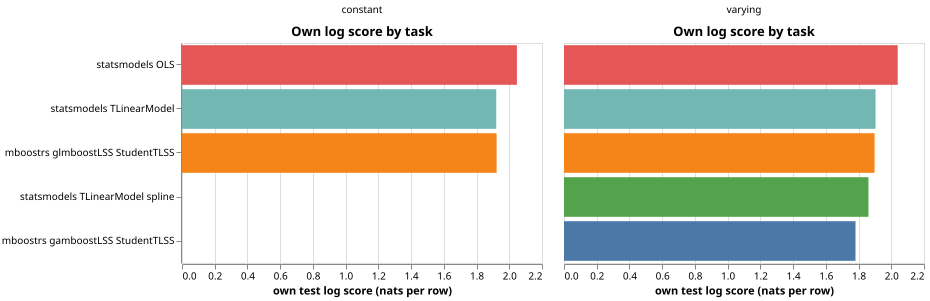

In [6]:
chart_rows = summary.filter(
    (pl.col("method") != "generating Student-t") & pl.col("own_nll").is_not_null()
)
alt.Chart(chart_rows).mark_bar().encode(
    x=alt.X("own_nll:Q", title="own test log score (nats per row)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=360,
    height=220,
    title="Own log score by task",
).facet(column=alt.Column("task:N", title=None))


## A constant scale

`glmboostLSS` with `StudentTLSS` matches `TLinearModel`. Mean own log score is {eval}`f"{value('constant', 'mboostrs glmboostLSS StudentTLSS', 'own_nll'):.4f}"` against {eval}`f"{value('constant', 'statsmodels TLinearModel', 'own_nll'):.4f}"` for the maximum likelihood estimate and {eval}`f"{value('constant', 'generating Student-t', 'own_nll'):.4f}"` for the generating density. OLS, scored on its own Gaussian density, is {eval}`f"{value('constant', 'statsmodels OLS', 'own_nll'):.4f}"`.

Scored at the generating scale and degrees of freedom, the three means are close: {eval}`f"{value('constant', 'mboostrs glmboostLSS StudentTLSS', 'nll_true'):.4f}"`, {eval}`f"{value('constant', 'statsmodels TLinearModel', 'nll_true'):.4f}"` and {eval}`f"{value('constant', 'statsmodels OLS', 'nll_true'):.4f}"`. The Gaussian gap is the density, not the mean. Absolute error of the mean is {eval}`f"{value('constant', 'mboostrs glmboostLSS StudentTLSS', 'mae'):.3f}"` against {eval}`f"{value('constant', 'statsmodels TLinearModel', 'mae'):.3f}"` and {eval}`f"{value('constant', 'statsmodels OLS', 'mae'):.3f}"`. Log-scale error is {eval}`f"{value('constant', 'mboostrs glmboostLSS StudentTLSS', 'mae_log_sigma'):.3f}"` against {eval}`f"{value('constant', 'statsmodels TLinearModel', 'mae_log_sigma'):.3f}"`. Mean estimated df is {eval}`f"{value('constant', 'mboostrs glmboostLSS StudentTLSS', 'df'):.2f}"` against {eval}`f"{value('constant', 'statsmodels TLinearModel', 'df'):.2f}"` (the truth is 4).

The mean chosen step is {eval}`f"{value('constant', 'mboostrs glmboostLSS StudentTLSS', 'mstop'):.0f}"` of 600, in {eval}`f"{value('constant', 'mboostrs glmboostLSS StudentTLSS', 'seconds'):.1f}"` seconds. `TLinearModel` takes {eval}`f"{value('constant', 'statsmodels TLinearModel', 'seconds'):.2f}"` seconds. On the first training sample, `logLik()` is {eval}`f"{bench['recovery']['lss_loglik']:.3f}"` and the t density at the same fit is {eval}`f"{bench['recovery']['lss_scipy_loglik']:.3f}"`. The df parameter took no boosting steps on that fit: the offset had already set it, and the number of boosting steps assigned to it was {eval}`str(bench['recovery']['lss_allocation'])`.


(a-scale-that-moves)=
## Varying scale

A linear model misses the sine. `glmboostLSS` scores {eval}`f"{value('varying', 'mboostrs glmboostLSS StudentTLSS', 'own_nll'):.3f}"` and the linear `TLinearModel` scores {eval}`f"{value('varying', 'statsmodels TLinearModel', 'own_nll'):.3f}"`, with absolute error of the mean about {eval}`f"{value('varying', 'mboostrs glmboostLSS StudentTLSS', 'mae'):.2f}"`. OLS scores {eval}`f"{value('varying', 'statsmodels OLS', 'own_nll'):.3f}"`.

`gamboostLSS` scores {eval}`f"{value('varying', 'mboostrs gamboostLSS StudentTLSS', 'own_nll'):.4f}"` against the generating density {eval}`f"{value('varying', 'generating Student-t', 'own_nll'):.4f}"` and a `TLinearModel` whose mean is a B-spline but whose scale is still one number, {eval}`f"{value('varying', 'statsmodels TLinearModel spline', 'own_nll'):.4f}"`. At the generating scale those two means agree, {eval}`f"{value('varying', 'mboostrs gamboostLSS StudentTLSS', 'nll_true'):.4f}"` against {eval}`f"{value('varying', 'statsmodels TLinearModel spline', 'nll_true'):.4f}"`, so the gap of about {eval}`f"{value('varying', 'statsmodels TLinearModel spline', 'own_nll') - value('varying', 'mboostrs gamboostLSS StudentTLSS', 'own_nll'):.2f}"` nats is the scale. Log-scale error is {eval}`f"{value('varying', 'mboostrs gamboostLSS StudentTLSS', 'mae_log_sigma'):.3f}"` against {eval}`f"{value('varying', 'statsmodels TLinearModel spline', 'mae_log_sigma'):.3f}"`. The spline fit's degrees of freedom fall to {eval}`f"{value('varying', 'statsmodels TLinearModel spline', 'df'):.2f}"`: variation in the scale is absorbed as a heavier tail. `gamboostLSS` keeps df at {eval}`f"{value('varying', 'mboostrs gamboostLSS StudentTLSS', 'df'):.2f}"`.

The mean chosen step is {eval}`f"{value('varying', 'mboostrs gamboostLSS StudentTLSS', 'mstop'):.0f}"` of 1,200, in {eval}`f"{value('varying', 'mboostrs gamboostLSS StudentTLSS', 'seconds'):.0f}"` seconds. No selected step sat on the cap.


## Prediction and parameter accessors

The calls below were made on the first constant-scale training sample.

`predict` defaults to `type="link"`. For `StudentTLSS` that is the mean, the log scale and the log degrees of freedom. {eval}`probe("predict default is mu, log sigma and log df")["detail"]` The benchmark uses `type="response"`.

`sigma` is the scale of the t distribution; its standard deviation is `sigma * sqrt(df / (df - 2))`. {eval}`probe("sigma is the t scale, not the standard deviation")["detail"]` `TLinearModel` uses the same scale: the scale of a standard t distribution.

`logLik()` is the t density. {eval}`probe("StudentTLSS logLik is the t density")["detail"]`

`offset` is on the link scale, so `offset["df"]` is a log degrees of freedom. {eval}`probe("offset is on the link scale")["detail"]`

A non-finite response is refused: {eval}`probe("a non-finite y is refused")["detail"]`

`glmboost(family=StudentTLSS())` reports that the family is undefined: {eval}`probe("glmboost does not take StudentTLSS")["detail"]`
